# Tanner graph of NESEN (22,3)
Build, visualize and count the short cycles of the X and Z Tanner graphs of NESEN (22,3).

In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp

import directional_tile_codes as dtc
from directional_tile_codes.visualize import X_COLOR, Z_COLOR, BOTH_COLOR, LAYOUT_COLOR, GRID_COLOR
from qldpc import circuits

CHECK_COLOR = {"X": X_COLOR, "Z": Z_COLOR}

## Code and parity-check matrices

In [3]:
code = dtc.DirectionalTileCode(M=22, N=3, word=dtc.DirectionalWord("NESEN"))
data, x_checks, z_checks = code.parity_checks
H = {"X": np.asarray(code.parity_check_matrices[0], dtype=int),
     "Z": np.asarray(code.parity_check_matrices[1], dtype=int)}

def weights(values):
    return {int(w): int(c) for w, c in sorted(Counter(values).items())}


print(f"[[n, k]] = [[{code.num_data_qubits}, {code.num_logical_qubits}]]")
for t, h in H.items():
    print(f"H_{t}: {h.shape[0]} checks x {h.shape[1]} qubits | "
          f"check weights {weights(h.sum(1))} | qubit degrees {weights(h.sum(0))}")

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


[[n, k]] = [[165, 2]]
H_X: 88 checks x 165 qubits | check weights {4: 44, 5: 44} | qubit degrees {1: 14, 2: 71, 3: 80}
H_Z: 75 checks x 165 qubits | check weights {2: 6, 4: 6, 5: 63} | qubit degrees {1: 48, 2: 48, 3: 69}


## Build the Tanner graphs
X and Z errors are decoded separately for a CSS code, so we build one graph per check type. Nodes are `("q", j)` for data qubits and `("X", i)` / `("Z", i)` for checks.

In [4]:
def tanner_graph(h: np.ndarray, check_type: str) -> nx.Graph:
    graph = nx.Graph()
    graph.add_nodes_from((("q", j) for j in range(h.shape[1])), bipartite=0)
    graph.add_nodes_from(((check_type, i) for i in range(h.shape[0])), bipartite=1)
    graph.add_edges_from(((check_type, i), ("q", j)) for i, j in zip(*np.nonzero(h)))
    return graph


G = {t: tanner_graph(h, t) for t, h in H.items()}
for t, g in G.items():
    print(f"{t}: {g.number_of_nodes()} nodes, {g.number_of_edges()} edges, "
          f"{nx.number_connected_components(g)} connected component(s)")

X: 253 nodes, 396 edges, 1 connected component(s)
Z: 240 nodes, 351 edges, 1 connected component(s)


## Visualization

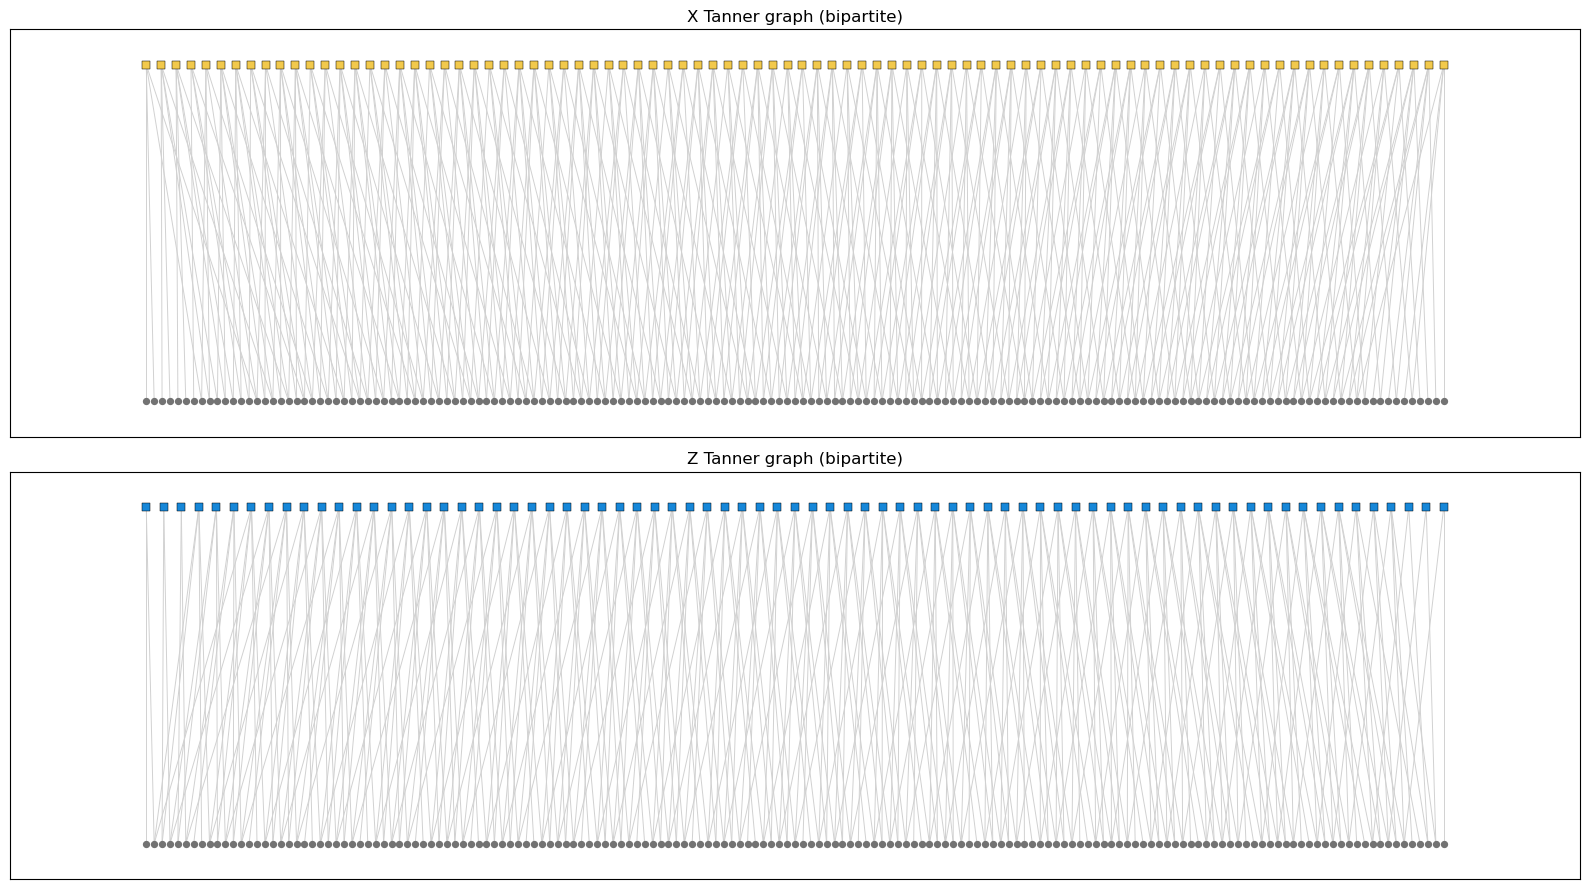

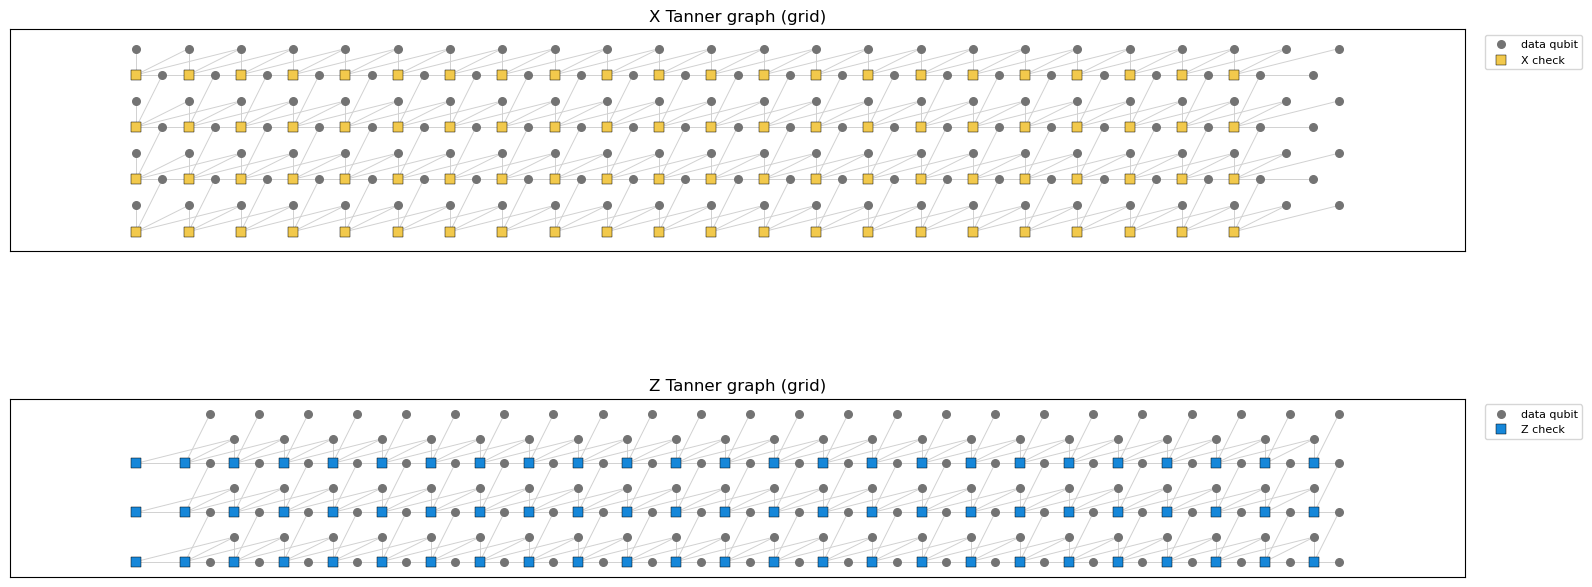

In [5]:
positions = {
    "q": [edge.middle for edge in data],
    "X": [anchor.add(code.x_tile.check_qubit) for anchor in x_checks],
    "Z": [anchor.add(code.z_tile.check_qubit) for anchor in z_checks],
}


def bipartite_layout(graph, check_type):
    n, m = len(positions["q"]), len(positions[check_type])
    pos = {("q", j): (j / (n - 1), 0.0) for j in range(n)}
    pos.update({(check_type, i): (i / (m - 1), 1.0) for i in range(m)})
    return pos


def grid_layout(graph, check_type):
    return {node: (positions[node[0]][node[1]].x, positions[node[0]][node[1]].y) for node in graph}


def draw_tanner(ax, graph, check_type, pos, size=18, show_qubits=True):
    qubits = [v for v in graph if v[0] == "q"] if show_qubits else []
    checks = [v for v in graph if v[0] == check_type]
    nx.draw_networkx_edges(graph, pos, ax=ax, edge_color=GRID_COLOR, width=0.7)
    if qubits:
        nx.draw_networkx_nodes(graph, pos, nodelist=qubits, ax=ax, node_color=LAYOUT_COLOR,
                               node_size=size, label="data qubit")
    nx.draw_networkx_nodes(graph, pos, nodelist=checks, ax=ax, node_color=CHECK_COLOR[check_type],
                           node_shape="s", node_size=1.6 * size, edgecolors="black", linewidths=0.35,
                           label=f"{check_type} check")


fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for ax, t in zip(axes, ("X", "Z")):
    draw_tanner(ax, G[t], t, bipartite_layout(G[t], t))
    ax.set_title(f"{t} Tanner graph (bipartite)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(16, 8))
for ax, t in zip(axes, ("X", "Z")):
    draw_tanner(ax, G[t], t, grid_layout(G[t], t), size=30)
    ax.set_aspect("equal")
    ax.set_title(f"{t} Tanner graph (grid)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.tight_layout()
plt.show()

## Girth and short cycles

In [6]:
MAX_LENGTH = 8

cycles = {t: list(nx.simple_cycles(g, length_bound=MAX_LENGTH)) for t, g in G.items()}

rows = []
for t, h in H.items():
    lengths = Counter(len(c) for c in cycles[t])
    rows.append({"graph": t, "girth": nx.girth(G[t]),
                 **{f"{L}-cycles": lengths[L] for L in range(4, MAX_LENGTH + 1, 2)}})
display(pd.DataFrame(rows).set_index("graph"))

,girth,4-cycles,6-cycles,8-cycles
graph,,,,
X,4,84,80,373
Z,4,66,63,280
